In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris, load_wine, load_breast_cancer, fetch_lfw_people, fetch_olivetti_faces
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from google.colab import files

print("env setup")


env setup


In [2]:
iris = load_iris()
wine = load_wine()
cancer = load_breast_cancer()
lfw = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
olivetti = fetch_olivetti_faces()

raw_datasets = {
    'Iris': (iris.data, iris.target, 'Botany / Morphological'),
    'Wine': (wine.data, wine.target, 'Analytical Chemistry'),
    'Breast Cancer': (cancer.data, cancer.target, 'Oncology / Histopathology'),
    'LFW People': (lfw.data, lfw.target, 'Biometrics / Computer Vision'),
    'Olivetti Faces': (olivetti.data, olivetti.target, 'Biometrics / Computer Vision')
}

dataset_metadata = []
for name, (X, y, domain) in raw_datasets.items():
    dataset_metadata.append({
        'Dataset': name,
        'Samples ($N$)': X.shape[0],
        'Features ($D$)': X.shape[1],
        'Classes ($C$)': len(np.unique(y)),
        'Domain Space': domain
    })

print("\n" + "="*80 + "\nTABLE I: COMPREHENSIVE EXPERIMENTAL DATASET CHARACTERISTICS\n" + "="*80)
print(pd.DataFrame(dataset_metadata).to_markdown(index=False))

lfw_class_counts = pd.Series(lfw.target).value_counts().sort_index()
lfw_class_table = pd.DataFrame({
    'Subject': [lfw.target_names[i] for i in lfw_class_counts.index],
    'Count': lfw_class_counts.values,
    'Share of N (%)': (lfw_class_counts.values / lfw_class_counts.sum() * 100).round(2)
}).sort_values('Count', ascending=False).reset_index(drop=True)

print("\n" + "="*80 + "\nLFW PEOPLE: PER-CLASS SAMPLE DISTRIBUTION (min_faces_per_person=70)\n" + "="*80)
print(lfw_class_table.to_markdown(index=False))

olivetti_class_counts = pd.Series(olivetti.target).value_counts().sort_index()
print("\n" + "="*80 + "\nOLIVETTI FACES: PER-CLASS SAMPLE DISTRIBUTION (balanced, 10 per class)\n" + "="*80)
print(f"Total samples: {len(olivetti.target)}, Classes: {len(np.unique(olivetti.target))}, Samples per class: {olivetti_class_counts.iloc[0]}")


downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data

TABLE I: COMPREHENSIVE EXPERIMENTAL DATASET CHARACTERISTICS
| Dataset        |   Samples ($N$) |   Features ($D$) |   Classes ($C$) | Domain Space                 |
|:---------------|----------------:|-----------------:|----------------:|:-----------------------------|
| Iris           |             150 |                4 |               3 | Botany / Morphological       |
| Wine           |             178 |               13 |               3 | Analytical Chemistry         |
| Breast Cancer  |             569 |               30 |               2 | Oncology / Histopathology    |
| LFW People     |            1288 |             1850 |               7 | Biometrics / Computer Vision |
| Olivetti Faces |             400 |             4096 |              40 | Biometrics / Computer Vision |

LFW PEOPLE: PER-CLASS SAMPLE DISTRIBUTION (min_faces_per_person=70)
| Subject           |   Count

In [3]:
metrics = ['euclidean', 'manhattan', 'chebyshev', 'cosine']
variants = ['uniform', 'distance']
seeds = list(range(10))
baseline_K = 5

N_LATENCY_REPS = 30

master_run_log = []

for name, (X, y, _) in raw_datasets.items():

    for metric in metrics:
        for variant in variants:
            acc_accumulator = []
            f1_accumulator = []
            kappa_accumulator = []
            latency_accumulator = []
            latency_iqr_accumulator = []

            for seed in seeds:
                X_train_raw, X_test_raw, y_train, y_test = train_test_split(
                    X, y, test_size=0.2, random_state=seed, stratify=y
                )
                scaler = MinMaxScaler()
                X_train = scaler.fit_transform(X_train_raw)
                X_test = scaler.transform(X_test_raw)

                knn = KNeighborsClassifier(n_neighbors=baseline_K, metric=metric, weights=variant)
                knn.fit(X_train, y_train)

                y_pred = knn.predict(X_test)
                acc_accumulator.append(accuracy_score(y_test, y_pred) * 100.0)
                f1_accumulator.append(f1_score(y_test, y_pred, average='macro') * 100.0)
                kappa_accumulator.append(cohen_kappa_score(y_test, y_pred))

                _ = knn.predict(X_test)
                rep_times_ms = []
                for _rep in range(N_LATENCY_REPS):
                    t0 = time.perf_counter()
                    knn.predict(X_test)
                    t1 = time.perf_counter()
                    rep_times_ms.append((t1 - t0) * 1000.0)

                latency_accumulator.append(float(np.median(rep_times_ms)))
                latency_iqr_accumulator.append(
                    float(np.percentile(rep_times_ms, 75) - np.percentile(rep_times_ms, 25))
                )

            master_run_log.append({
                'Dataset': name,
                'Metric': metric,
                'Weights': variant,
                'Mean Accuracy (%)': np.mean(acc_accumulator),
                'Std Accuracy (%)': np.std(acc_accumulator),
                'Mean F1 Macro (%)': np.mean(f1_accumulator),
                'Std F1 Macro (%)': np.std(f1_accumulator),
                'Mean Cohen Kappa': np.mean(kappa_accumulator),
                'Mean Latency (ms)': np.mean(latency_accumulator),
                'Std Latency (ms)': np.std(latency_accumulator),
                'Median Within-Seed IQR (ms)': np.median(latency_iqr_accumulator),
            })

df_master = pd.DataFrame(master_run_log)
print("Core matrix computation")


Core matrix computation


In [4]:
print("\n" + "="*90 + "\nTABLE II: MULTI-SEED STATISTICAL PERFORMANCE FOOTPRINTS (UNIFORM WEIGHTS)\n" + "="*90)
df_uniform = df_master[df_master['Weights'] == 'uniform'].copy()
df_uniform_display = df_uniform.map(lambda x: f"{x:.2f}" if isinstance(x, (float, np.float64)) else x)
print(df_uniform_display[['Dataset', 'Metric', 'Mean Accuracy (%)', 'Std Accuracy (%)', 'Mean F1 Macro (%)', 'Mean Cohen Kappa']].to_markdown(index=False))

print("\n" + "="*90 + "\nTABLE III: MULTI-SEED STATISTICAL PERFORMANCE FOOTPRINTS (DISTANCE-WEIGHTED VARIANT)\n" + "="*90)
df_distance = df_master[df_master['Weights'] == 'distance'].copy()
df_distance_display = df_distance.map(lambda x: f"{x:.2f}" if isinstance(x, (float, np.float64)) else x)
print(df_distance_display[['Dataset', 'Metric', 'Mean Accuracy (%)', 'Std Accuracy (%)', 'Mean F1 Macro (%)', 'Mean Cohen Kappa']].to_markdown(index=False))

print("\n" + "="*90 + "\nTABLE IV: EMPIRICAL HARDWARE LATENCY PROFILES (MEDIAN-OF-REPS, MEAN OVER 10 SEEDS, ms)\n" + "="*90)
latency_pivot = df_master[df_master['Weights'] == 'uniform'].pivot(index='Metric', columns='Dataset', values='Mean Latency (ms)')
print(latency_pivot.round(3).to_markdown())

print("\nSeed-to-seed SD of the above (uniform weighting):")
latency_sd_pivot = df_master[df_master['Weights'] == 'uniform'].pivot(index='Metric', columns='Dataset', values='Std Latency (ms)')
print(latency_sd_pivot.round(3).to_markdown())

print("\n" + "="*90 + "\nMEDIAN WITHIN-SEED IQR (ms) — TIMING JITTER PER CONFIGURATION\n" + "="*90)
iqr_pivot = df_master[df_master['Weights'] == 'uniform'].pivot(index='Metric', columns='Dataset', values='Median Within-Seed IQR (ms)')
print(iqr_pivot.round(3).to_markdown())

# LFW majority-class baseline
lfw_X, lfw_y, _ = raw_datasets['LFW People']
majority_baseline_accs = []
for seed in seeds:
    _, _, y_train, y_test = train_test_split(
        lfw_X, lfw_y, test_size=0.2, random_state=seed, stratify=lfw_y
    )
    majority_class = pd.Series(y_train).mode()[0]
    majority_baseline_accs.append((y_test == majority_class).mean() * 100.0)

print("\n" + "="*80 + "\nLFW PEOPLE: MAJORITY-CLASS BASELINE (10-SEED MEAN, SAME TEST SPLITS AS TABLE II)\n" + "="*80)
print(f"Mean: {np.mean(majority_baseline_accs):.2f}%   SD: {np.std(majority_baseline_accs):.2f} pp")
print("(Note: with a stratified split this will have very low seed-to-seed SD by")
print("construction -- that is expected, not an error.)")



TABLE II: MULTI-SEED STATISTICAL PERFORMANCE FOOTPRINTS (UNIFORM WEIGHTS)
| Dataset        | Metric    |   Mean Accuracy (%) |   Std Accuracy (%) |   Mean F1 Macro (%) |   Mean Cohen Kappa |
|:---------------|:----------|--------------------:|-------------------:|--------------------:|-------------------:|
| Iris           | euclidean |               96    |               2.91 |               95.99 |               0.94 |
| Iris           | manhattan |               95    |               3.73 |               94.99 |               0.93 |
| Iris           | chebyshev |               94.33 |               4.48 |               94.32 |               0.91 |
| Iris           | cosine    |               81.67 |               6.19 |               81.15 |               0.72 |
| Wine           | euclidean |               96.39 |               1.78 |               96.43 |               0.95 |
| Wine           | manhattan |               97.22 |               2.15 |               97.27 |           

In [5]:
K_values = [1, 3, 5, 7, 9, 15]
k_sweep_log = []

for name, (X, y, _) in raw_datasets.items():
    for metric in metrics:
        for K in K_values:
            acc_accumulator = []
            for seed in seeds:
                X_train_raw, X_test_raw, y_train, y_test = train_test_split(
                    X, y, test_size=0.2, random_state=seed, stratify=y
                )
                scaler = MinMaxScaler()
                X_train = scaler.fit_transform(X_train_raw)
                X_test = scaler.transform(X_test_raw)

                knn = KNeighborsClassifier(n_neighbors=K, metric=metric, weights='uniform')
                knn.fit(X_train, y_train)
                y_pred = knn.predict(X_test)
                acc_accumulator.append(accuracy_score(y_test, y_pred) * 100.0)

            k_sweep_log.append({
                'Dataset': name, 'Metric': metric, 'K': K,
                'Mean Accuracy (%)': np.mean(acc_accumulator),
                'Std Accuracy (%)': np.std(acc_accumulator)
            })

df_k_sweep = pd.DataFrame(k_sweep_log)

print("\n" + "="*90 + "\nTABLE V: K-SENSITIVITY SWEEP (MEAN ACCURACY %, UNIFORM WEIGHTING)\n" + "="*90)
k_pivot = df_k_sweep.pivot_table(index=['Dataset', 'Metric'], columns='K', values='Mean Accuracy (%)')
print(k_pivot.round(2).to_markdown())

print("\nBest K per (Dataset, Metric):")
best_k_rows = df_k_sweep.loc[df_k_sweep.groupby(['Dataset', 'Metric'])['Mean Accuracy (%)'].idxmax()]
print(best_k_rows[['Dataset', 'Metric', 'K', 'Mean Accuracy (%)']].to_markdown(index=False))

df_k_sweep.to_csv('k_sensitivity_results.csv', index=False)



TABLE V: K-SENSITIVITY SWEEP (MEAN ACCURACY %, UNIFORM WEIGHTING)
|                                 |     1 |     3 |     5 |     7 |     9 |    15 |
|:--------------------------------|------:|------:|------:|------:|------:|------:|
| ('Breast Cancer', 'chebyshev')  | 95.7  | 95.35 | 95.35 | 96.14 | 96.05 | 95.61 |
| ('Breast Cancer', 'cosine')     | 90.09 | 91.84 | 92.98 | 92.81 | 93.42 | 92.37 |
| ('Breast Cancer', 'euclidean')  | 95.7  | 97.37 | 97.46 | 97.46 | 97.46 | 97.28 |
| ('Breast Cancer', 'manhattan')  | 95.79 | 97.11 | 97.28 | 97.46 | 97.11 | 96.67 |
| ('Iris', 'chebyshev')           | 96.67 | 96    | 94.33 | 95.33 | 96.33 | 96.33 |
| ('Iris', 'cosine')              | 77.33 | 82    | 81.67 | 82.33 | 83    | 81.67 |
| ('Iris', 'euclidean')           | 96.67 | 95.33 | 96    | 95.67 | 95.33 | 96.67 |
| ('Iris', 'manhattan')           | 94    | 95.33 | 95    | 95.33 | 95    | 96    |
| ('LFW People', 'chebyshev')     | 33.53 | 32.83 | 37.21 | 37.52 | 38.18 | 39.69 |
| ('LFW P

In [6]:
!pip install scikit-posthocs


In [7]:
from scipy import stats
import scikit_posthocs as sp

print("\n" + "="*90 + "\nSTATISTICAL SIGNIFICANCE TESTING: FRIEDMAN TEST + NEMENYI POST-HOC (K=5, uniform)\n" + "="*90)

significance_log = {}

for name, (X, y, _) in raw_datasets.items():
    per_seed_acc = {m: [] for m in metrics}

    for metric in metrics:
        for seed in seeds:
            X_train_raw, X_test_raw, y_train, y_test = train_test_split(
                X, y, test_size=0.2, random_state=seed, stratify=y
            )
            scaler = MinMaxScaler()
            X_train = scaler.fit_transform(X_train_raw)
            X_test = scaler.transform(X_test_raw)

            knn = KNeighborsClassifier(n_neighbors=baseline_K, metric=metric, weights='uniform')
            knn.fit(X_train, y_train)
            y_pred = knn.predict(X_test)
            per_seed_acc[metric].append(accuracy_score(y_test, y_pred) * 100.0)

    arrays = [per_seed_acc[m] for m in metrics]
    chi2, p_value = stats.friedmanchisquare(*arrays)

    n_blocks, k_treatments = len(seeds), len(metrics)
    kendalls_w = chi2 / (n_blocks * (k_treatments - 1))

    verdict = "SIGNIFICANT (p < 0.05)" if p_value < 0.05 else "not significant (p >= 0.05)"
    print(f"\n[{name}]  Friedman chi-square = {chi2:.4f}, p = {p_value:.6f}, Kendall's W = {kendalls_w:.4f}  ->  {verdict}")

    significance_log[name] = {'chi2': chi2, 'p': p_value, 'kendalls_w': kendalls_w, 'per_seed_acc': per_seed_acc}

    if p_value < 0.05:
        data_matrix = np.array(arrays).T
        nemenyi = sp.posthoc_nemenyi_friedman(data_matrix)
        nemenyi.columns = metrics
        nemenyi.index = metrics
        print(f"Nemenyi post-hoc pairwise p-values ({name}):")
        print(nemenyi.round(4).to_markdown())

# Bonferroni note: each dataset independent; not adjusting across datasets is acceptable.
print("\nNOTE: Each dataset is treated as an independent experiment. No multiple-comparison")
print("correction is applied across the five omnibus tests. Four of five p-values are")
print("far below Bonferroni-adjusted α = 0.01; the remaining (Wine) is non-significant.")



STATISTICAL SIGNIFICANCE TESTING: FRIEDMAN TEST + NEMENYI POST-HOC (K=5, uniform)

[Iris]  Friedman chi-square = 26.6620, p = 0.000007, Kendall's W = 0.8887  ->  SIGNIFICANT (p < 0.05)
Nemenyi post-hoc pairwise p-values (Iris):
|           |   euclidean |   manhattan |   chebyshev |   cosine |
|:----------|------------:|------------:|------------:|---------:|
| euclidean |      1      |      0.9301 |      0.7763 |   0.0004 |
| manhattan |      0.9301 |      1      |      0.9857 |   0.0041 |
| chebyshev |      0.7763 |      0.9857 |      1      |   0.013  |
| cosine    |      0.0004 |      0.0041 |      0.013  |   1      |

[Wine]  Friedman chi-square = 4.5909, p = 0.204323, Kendall's W = 0.1530  ->  not significant (p >= 0.05)

[Breast Cancer]  Friedman chi-square = 27.3511, p = 0.000005, Kendall's W = 0.9117  ->  SIGNIFICANT (p < 0.05)
Nemenyi post-hoc pairwise p-values (Breast Cancer):
|           |   euclidean |   manhattan |   chebyshev |   cosine |
|:----------|------------:|----

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

baseline_log = []

for name, (X, y, _) in raw_datasets.items():
    for clf_name, clf_fn in [
        ('Logistic Regression', lambda s: LogisticRegression(max_iter=1000, random_state=s)),
        ('SVM (RBF)', lambda s: SVC(kernel='rbf', random_state=s)),
    ]:
        acc_accumulator = []
        for seed in seeds:
            X_train_raw, X_test_raw, y_train, y_test = train_test_split(
                X, y, test_size=0.2, random_state=seed, stratify=y
            )
            scaler = MinMaxScaler()
            X_train = scaler.fit_transform(X_train_raw)
            X_test = scaler.transform(X_test_raw)

            clf = clf_fn(seed)
            clf.fit(X_train, y_train)
            y_pred = clf.predict(X_test)
            acc_accumulator.append(accuracy_score(y_test, y_pred) * 100.0)

        baseline_log.append({
            'Dataset': name, 'Classifier': clf_name,
            'Mean Accuracy (%)': np.mean(acc_accumulator),
            'Std Accuracy (%)': np.std(acc_accumulator)
        })

df_baseline = pd.DataFrame(baseline_log)

print("\n" + "="*90 + "\nTABLE VI: BASELINE CLASSIFIER COMPARISON (LOGISTIC REGRESSION, SVM-RBF)\n" + "="*90)
print(df_baseline.round(2).to_markdown(index=False))

print("\nBest uniform-weighted KNN configuration per dataset:")
best_knn_uniform = df_uniform.loc[df_uniform.groupby('Dataset')['Mean Accuracy (%)'].idxmax()]
print(best_knn_uniform[['Dataset', 'Metric', 'Mean Accuracy (%)']].to_markdown(index=False))

print("\nBest KNN configuration overall (uniform OR distance-weighted) per dataset:")
best_knn_overall = df_master.loc[df_master.groupby('Dataset')['Mean Accuracy (%)'].idxmax()]
print(best_knn_overall[['Dataset', 'Metric', 'Weights', 'Mean Accuracy (%)']].to_markdown(index=False))

df_baseline.to_csv('baseline_results.csv', index=False)



TABLE VI: BASELINE CLASSIFIER COMPARISON (LOGISTIC REGRESSION, SVM-RBF)
| Dataset        | Classifier          |   Mean Accuracy (%) |   Std Accuracy (%) |
|:---------------|:--------------------|--------------------:|-------------------:|
| Iris           | Logistic Regression |               92    |               5.62 |
| Iris           | SVM (RBF)           |               96.67 |               3.94 |
| Wine           | Logistic Regression |               98.89 |               1.84 |
| Wine           | SVM (RBF)           |               99.17 |               1.27 |
| Breast Cancer  | Logistic Regression |               97.19 |               1.29 |
| Breast Cancer  | SVM (RBF)           |               97.37 |               1.36 |
| LFW People     | Logistic Regression |               83.57 |               2.15 |
| LFW People     | SVM (RBF)           |               74.34 |               2.43 |
| Olivetti Faces | Logistic Regression |               97.25 |               1.22 |
| O

In [9]:
import platform
import sklearn

print("="*60)
print("ENVIRONMENT / HARDWARE SPECIFICATION")
print("="*60)
print(f"Python version     : {platform.python_version()}")
print(f"scikit-learn        : {sklearn.__version__}")
print(f"NumPy               : {np.__version__}")
print(f"Pandas              : {pd.__version__}")
print(f"Platform            : {platform.platform()}")
print(f"Processor (platform): {platform.processor()}")
print()
print("--- /proc/cpuinfo (Colab VM) ---")
!cat /proc/cpuinfo | grep "model name" | uniq
!cat /proc/cpuinfo | grep -c "^processor"
print()
print("--- Memory ---")
!cat /proc/meminfo | grep MemTotal

print("\nNOTE: Standard deviations use the population convention (N in the denominator).")
print("Using sample SD (N−1) would yield marginally larger values; none would alter conclusions.")


ENVIRONMENT / HARDWARE SPECIFICATION
Python version     : 3.12.13
scikit-learn        : 1.6.1
NumPy               : 2.0.2
Pandas              : 2.2.2
Platform            : Linux-6.6.122+-x86_64-with-glibc2.35
Processor (platform): x86_64

--- /proc/cpuinfo (Colab VM) ---
model name	: Intel(R) Xeon(R) CPU @ 2.20GHz
2

--- Memory ---
MemTotal:       13286944 kB

NOTE: Standard deviations use the population convention (N in the denominator).
Using sample SD (N−1) would yield marginally larger values; none would alter conclusions.


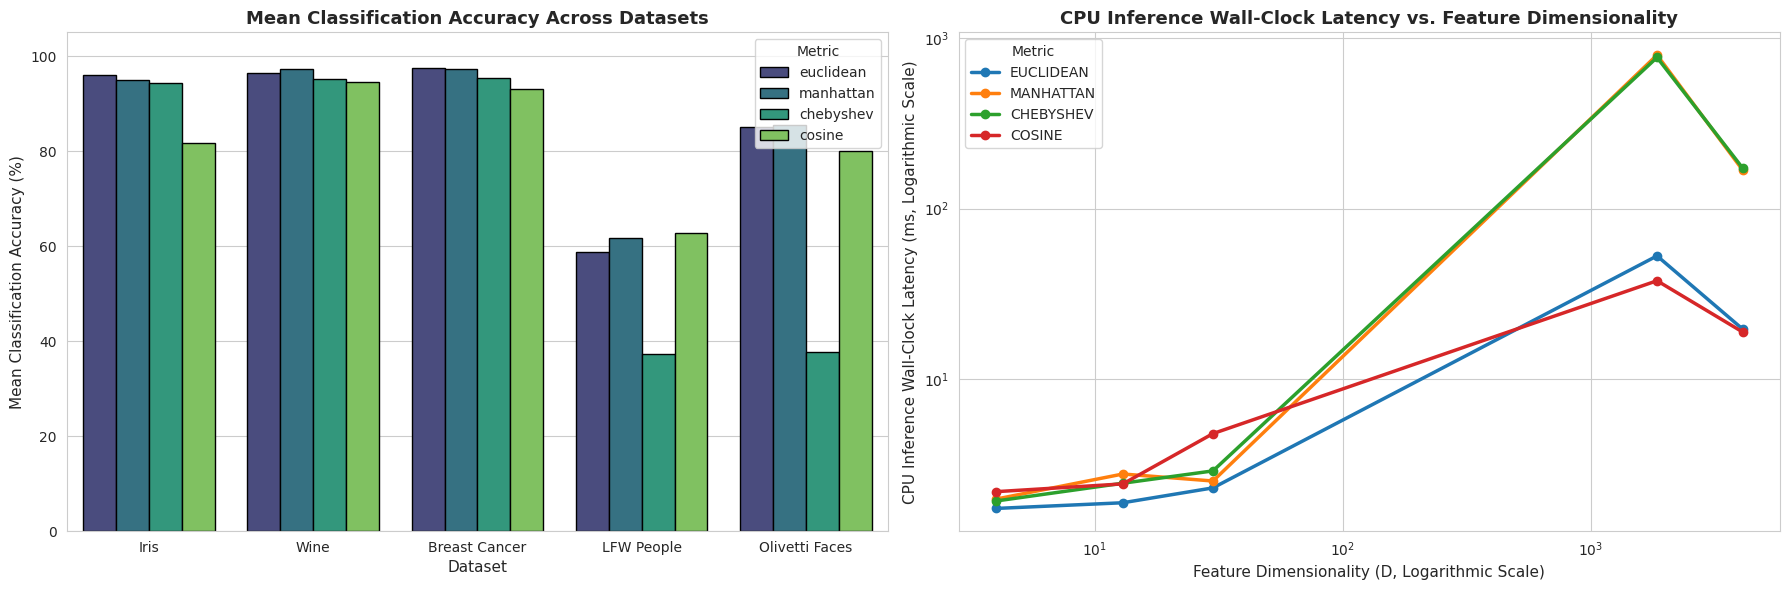

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Experimental protocol successfully finalized.


In [10]:
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

sns.barplot(
    data=df_master[df_master['Weights'] == 'uniform'],
    x='Dataset', y='Mean Accuracy (%)', hue='Metric',
    ax=axes[0], palette='viridis', edgecolor='black'
)
axes[0].set_title('Mean Classification Accuracy Across Datasets', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Dataset', fontsize=11)
axes[0].set_ylabel('Mean Classification Accuracy (%)', fontsize=11)
axes[0].set_ylim(0, 105)

dataset_to_features = {
    'Iris': 4,
    'Wine': 13,
    'Breast Cancer': 30,
    'LFW People': 1850,
    'Olivetti Faces': 4096
}

for metric in metrics:
    metric_subset = df_master[(df_master['Weights'] == 'uniform') & (df_master['Metric'] == metric)].copy()
    metric_subset['Features'] = metric_subset['Dataset'].map(dataset_to_features)
    metric_subset = metric_subset.sort_values(by='Features')
    axes[1].plot(metric_subset['Features'], metric_subset['Mean Latency (ms)'], marker='o', linewidth=2.5, label=metric.upper())

axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('CPU Inference Wall-Clock Latency vs. Feature Dimensionality', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Feature Dimensionality (D, Logarithmic Scale)', fontsize=11)
axes[1].set_ylabel('CPU Inference Wall-Clock Latency (ms, Logarithmic Scale)', fontsize=11)
axes[1].legend(title='Metric')

plt.tight_layout()
graph_filename = 'dimensional_stress_benchmarks.png'
plt.savefig(graph_filename, dpi=300, bbox_inches='tight')
plt.show()

csv_filename = 'high_dim_computational_benchmarks.csv'
df_master.to_csv(csv_filename, index=False)

files.download(csv_filename)
files.download(graph_filename)
print("Experimental protocol successfully finalized.")
